必要なライブラリとモジュールのインストール

In [1]:
#セル１
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import tkinter as tk
from tkinter import filedialog
import warnings

# 警告を非表示
warnings.simplefilter(action='ignore', category=FutureWarning)

# --- フォント設定 ---
font_file_path = r"C:\Users\0uh2j\OneDrive\Desktop\IPAexfont00401\ipaexg.ttf"
if os.path.exists(font_file_path):
    try:
        fm.fontManager.addfont(font_file_path)
        font_prop = fm.FontProperties(fname=font_file_path)
        plt.rcParams['font.family'] = font_prop.get_name()
        print(f"フォント適用: {font_prop.get_name()}")
    except Exception as e:
        print(f"フォント設定エラー: {e}")
else:
    print("デフォルトフォントを使用します。")

フォント適用: IPAexGothic


学習データファイル(CSVファイル)選択

In [2]:
#セル2
root = tk.Tk()
root.withdraw()
print("分析するCSVファイルを選択してください...")
csv_file_path = filedialog.askopenfilename(
    title="CSVファイルを選択してください",
    filetypes=[("CSVファイル", "*.csv"), ("すべてのファイル", "*.*")]
)
data_loaded = False

分析するCSVファイルを選択してください...


データ読み込みと前処理

In [3]:
#セル3

if csv_file_path:
    try:
        df = pd.read_csv(csv_file_path)
        
        # 列名の定義
        col_temp = '流動中樹脂温度T3(℃)'
        col_pres = '流動中樹脂圧力P23(Pa)'
        col_sr = 'せん断速度γ23(1/s)'
        col_visc = '樹脂粘度η23(Pa・s)'
        
        required_columns = [col_temp, col_pres, col_sr, col_visc]
        if not all(col in df.columns for col in required_columns):
            raise ValueError(f"必要な列が不足しています: {required_columns}")

        # 前処理 (単位変換と対数変換)
        df['流動中樹脂温度T3(K)'] = df[col_temp] + 273.15
        
        # ログ計算用の一時変数
        # ※インデックスを保持するためにdfに新しい列として追加する方法もありますが、
        # ここではシンプルに配列として処理し、インデックス管理は後で行います。
        log_T = np.log(df['流動中樹脂温度T3(K)'].values)
        log_P = np.log(df[col_pres].values)
        log_SR = np.log(df[col_sr].values)
        log_VISC = np.log(df[col_visc].values)
        
        # 入力データ X と目的変数 y の作成
        X_raw = np.stack([log_T, log_P, log_SR], axis=1)
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_raw)
        
        y_mean = log_VISC.mean()
        y_centered = log_VISC - y_mean
        
        data_loaded = True
        print(f"データ読み込み完了: 全 {len(X_scaled)} 件")
        
    except Exception as e:
        print(f"エラーが発生しました: {e}")

データ読み込み完了: 全 1076 件


学習データとテストデータの分割設定(公差検証法)

In [4]:
# セル4: 【重要】学習データとテストデータの分割設定 (範囲指定対応版)
if data_loaded:
    print("--- データの分割設定 ---")

    # ==========================================================
    # ▼▼▼ 設定エリア：ここで分割方法を決定してください ▼▼▼
    
    # モード選択: "random" または "condition"
    split_mode = "condition" 
    
    # 【設定A】 "random" の場合の設定
    test_ratio = 0.2  # テストデータの割合 (0.2 = 20%)
    
    # 【設定B】 "condition" の場合の設定 (範囲指定)
    # 指定した「下限値」から「上限値」の範囲内にあるデータをテスト用(検証用)にします。
    # それ以外のデータ(範囲外)を使って学習を行います。
    # 例: 温度が 200℃ 〜 210℃ のデータをテスト用にくり抜く場合
    
    target_column = 'せん断速度γ23(1/s)' # 条件を判断する列名
    
    test_range_min = 6000   # テストデータにする範囲の下限
    test_range_max = 7000   # テストデータにする範囲の上限
    
    # ▲▲▲ 設定エリア終了 ▲▲▲
    # ==========================================================

    indices = np.arange(len(X_scaled))

    if split_mode == "random":
        # ランダム分割
        X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
            X_scaled, y_centered, indices, test_size=test_ratio, random_state=42
        )
        print(f"【ランダム分割モード】 全体の {test_ratio*100}% をテストデータにしました。")

    elif split_mode == "condition":
        # 条件指定分割 (範囲指定)
        # ターゲット列の値を取得
        target_values = df[target_column].values
        
        # 範囲内 (min <= x <= max) をテストデータとするマスクを作成
        test_mask = (target_values >= test_range_min) & (target_values <= test_range_max)
        
        condition_str = f"{test_range_min} <= {target_column} <= {test_range_max}"
            
        idx_test = indices[test_mask]
        idx_train = indices[~test_mask] # maskの反転(Not) = 学習データ
        
        # エラーチェック
        if len(idx_test) == 0:
            print(f"【警告】指定された範囲({condition_str})にデータが1件もありません。")
            print("設定を見直すか、範囲を広げてください。")
        elif len(idx_train) == 0:
            print(f"【警告】全てのデータがテスト範囲に含まれてしまいました。学習できるデータがありません。")
            print("範囲を狭めてください。")
        else:
            X_train = X_scaled[idx_train]
            y_train = y_centered[idx_train]
            X_test = X_scaled[idx_test]
            y_test = y_centered[idx_test]
            print(f"【条件指定モード(範囲)】")
            print(f"条件: 「{condition_str}」 のデータをテスト(検証)用にしました。")
            print(f"それ以外のデータを学習に使用します。")

    # データ数の表示
    if 'X_train' in locals() and 'X_test' in locals():
        print(f"  - 学習用データ数: {len(X_train)} 件")
        print(f"  - テスト用データ数: {len(X_test)} 件")
        # 学習実行フラグ
        ready_to_train = len(X_train) > 0 and len(X_test) > 0
    else:
        ready_to_train = False

--- データの分割設定 ---
【条件指定モード(範囲)】
条件: 「6000 <= せん断速度γ23(1/s) <= 7000」 のデータをテスト(検証)用にしました。
それ以外のデータを学習に使用します。
  - 学習用データ数: 1005 件
  - テスト用データ数: 71 件


機械学習モデル構築と学習

In [5]:
#セル5学習モデル構築設定と学習過程

from scipy.optimize import minimize

# 進捗表示用コールバック
def custom_optimizer(obj_func, initial_theta, bounds):
    print(f"  > 最適化計算中", end="")
    def callback(xk):
        print(".", end="", flush=True)
    res = minimize(obj_func, initial_theta, bounds=bounds, method="L-BFGS-B", jac=True, callback=callback)
    print(" 完了")
    return res.x, res.fun

if data_loaded and ready_to_train:
    print("\n--- 学習プロセス開始 (scikit-learn) ---")
    
    # 計算負荷軽減のため、学習データが2000件を超える場合はダウンサンプリング
    N_MAX_TRAIN = 2000
    if len(X_train) > N_MAX_TRAIN:
        print(f"※学習データ({len(X_train)})が多いため、ランダムに{N_MAX_TRAIN}件を使用してモデル構築します。")
        fit_indices = np.random.choice(len(X_train), N_MAX_TRAIN, replace=False)
        X_train_fit = X_train[fit_indices]
        y_train_fit = y_train[fit_indices]
    else:
        X_train_fit = X_train
        y_train_fit = y_train

    # ARDカーネル定義
    kernel = C(1.0, (1e-3, 1e3)) * RBF(length_scale=[1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e2)) + \
             WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 1e1))
    
    gp_model = GaussianProcessRegressor(
        kernel=kernel, 
        n_restarts_optimizer=5, # 進捗が見えるので回数は適度でOK
        optimizer=custom_optimizer,
        random_state=42
    )
    
    # 学習実行
    gp_model.fit(X_train_fit, y_train_fit)
    
    print("--- 学習完了 ---")
    print(f"獲得したカーネル: {gp_model.kernel_}")
    learning_completed = True


--- 学習プロセス開始 (scikit-learn) ---
  > 最適化計算中....................... 完了
  > 最適化計算中..................... 完了
  > 最適化計算中...................... 完了
  > 最適化計算中........................... 完了
  > 最適化計算中............. 完了
  > 最適化計算中................ 完了
--- 学習完了 ---
獲得したカーネル: 0.684**2 * RBF(length_scale=[0.549, 0.305, 1.33]) + WhiteKernel(noise_level=8.09e-05)


予測分布グラフ(粘度に対するそれぞれの説明変数の依存性グラフ)


--- 変数ごとの依存性プロット ---


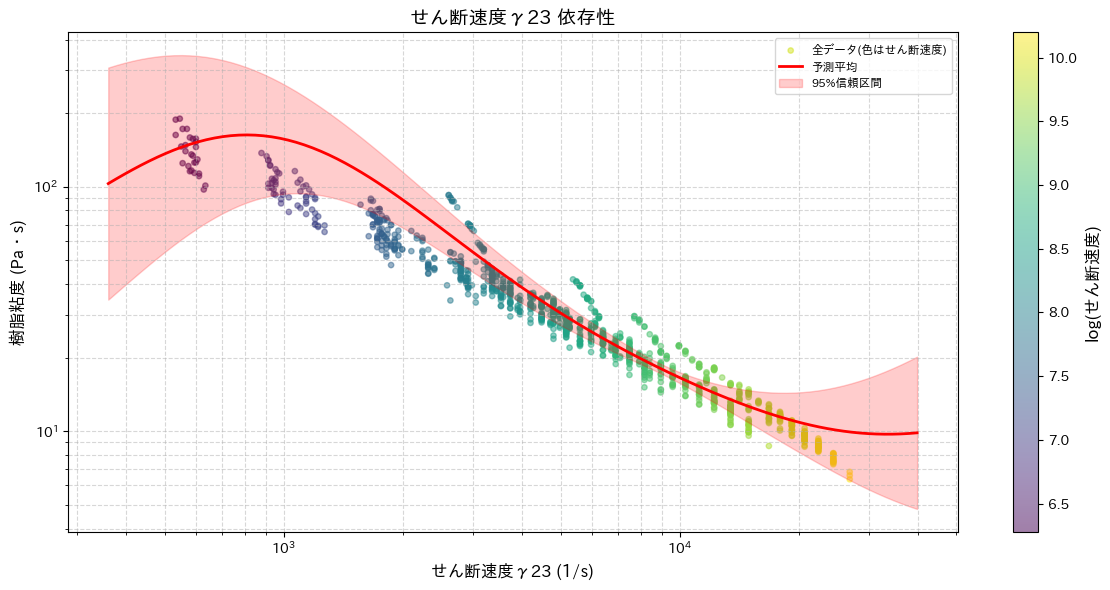

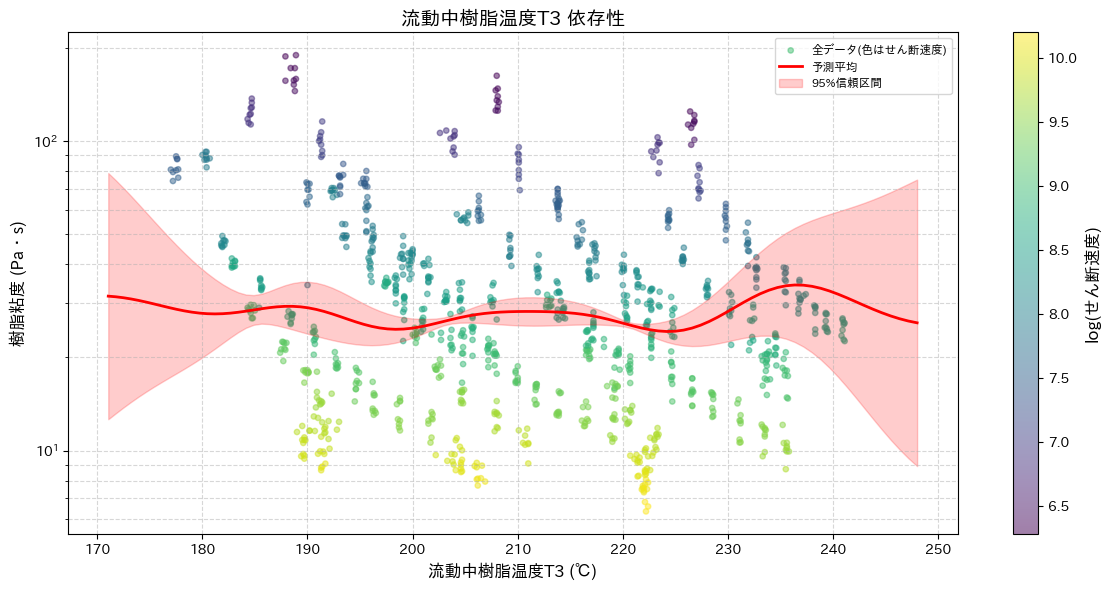

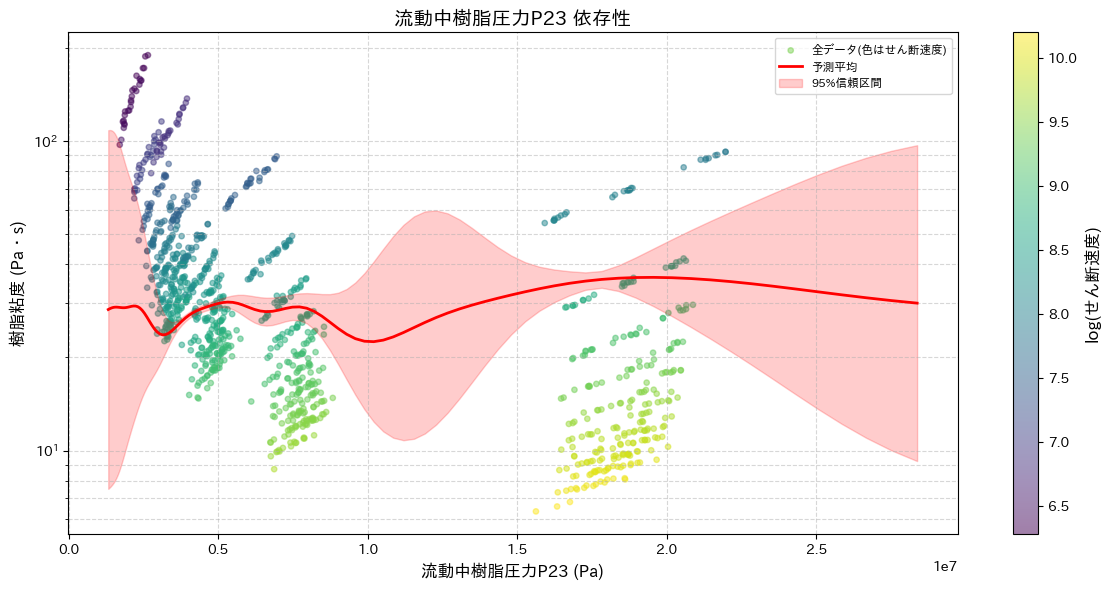

In [6]:
#セル6目的変数に対する各説明変数の依存性グラフ

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

if learning_completed:
    # === 2. 依存性プロット (傾向確認・個別出力版) ===
    print("\n--- 変数ごとの依存性プロット ---")
    
    # 【設定項目】グラフサイズをここで一括設定できます (幅, 高さ)
    common_figsize = (12, 6)
    
    # 表示設定
    plot_configs = [
        {'name': 'せん断速度γ23',    'unit': '(1/s)', 'data_idx': 2},
        {'name': '流動中樹脂温度T3',  'unit': '(℃)',   'data_idx': 0},
        {'name': '流動中樹脂圧力P23',  'unit': '(Pa)',  'data_idx': 1}
    ]
    
    n_grid = 100
    
    # --- 色分け設定 (せん断速度に基づく) ---
    shear_rates_log_all = X_raw[:, 2] 
    norm = plt.Normalize(vmin=shear_rates_log_all.min(), vmax=shear_rates_log_all.max())
    cmap = 'viridis' 
    
    for i, config in enumerate(plot_configs):
        # 1つずつ個別のFigureを作成
        fig, ax = plt.subplots(figsize=common_figsize)
        
        d_idx = config['data_idx']
        var_name = config['name']
        
        # 予測用グリッド作成
        x_min, x_max = X_scaled[:, d_idx].min(), X_scaled[:, d_idx].max()
        padding = (x_max - x_min) * 0.1
        x_grid = np.linspace(x_min - padding, x_max + padding, n_grid)
        
        X_new_scaled = np.zeros((n_grid, 3))
        X_new_scaled[:, d_idx] = x_grid
        
        # 予測
        y_pred, y_std = gp_model.predict(X_new_scaled, return_std=True)
        
        # 逆変換
        visc_mean = np.exp(y_pred + y_mean)
        visc_lower = np.exp(y_pred - 1.96*y_std + y_mean)
        visc_upper = np.exp(y_pred + 1.96*y_std + y_mean)
        
        x_grid_real = np.exp(x_grid * scaler.scale_[d_idx] + scaler.mean_[d_idx])
        if d_idx == 0: x_grid_real -= 273.15
            
        # 学習データのプロット 
        idx_sample = np.random.choice(len(X_raw), size=min(2000, len(X_raw)), replace=False)
        x_raw_sample = np.exp(X_raw[idx_sample, d_idx])
        y_raw_sample = np.exp(y_centered[idx_sample] + y_mean)
        c_sample = X_raw[idx_sample, 2] # logせん断速度
        
        if d_idx == 0: x_raw_sample -= 273.15
            
        # 散布図プロット
        sc = ax.scatter(x_raw_sample, y_raw_sample, c=c_sample, cmap=cmap, norm=norm,
                        alpha=0.5, s=15, label='全データ(色はせん断速度)')
        
        ax.plot(x_grid_real, visc_mean, color='red', linewidth=2, label='予測平均')
        ax.fill_between(x_grid_real, visc_lower, visc_upper, color='red', alpha=0.2, label='95%信頼区間')
        
        ax.set_title(f"{var_name} 依存性", fontsize=14)
        ax.set_xlabel(f"{var_name} {config['unit']}", fontsize=12)
        ax.set_ylabel("樹脂粘度 (Pa・s)", fontsize=12)
        ax.set_yscale('log')
        
        # せん断速度のグラフの場合の設定（10の整数乗のみ表示）
        if d_idx == 2: 
            ax.set_xscale('log')
            ax.xaxis.set_major_locator(ticker.LogLocator(base=10.0))
            ax.xaxis.set_major_formatter(ticker.LogFormatterSciNotation())
            ax.xaxis.set_minor_formatter(ticker.NullFormatter())
            ax.tick_params(axis='x', which='major', rotation=0, labelsize=10)

        ax.grid(True, which="both", linestyle='--', alpha=0.5)
        ax.legend(loc='upper right', fontsize='small')
        
        # カラーバーを追加
        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label('log(せん断速度)', fontsize=12)

        # ループ内でその都度表示
        plt.tight_layout()
        plt.show()

結果の検証（パリティプロット）


--- 検証結果の可視化 (精度検証) ---


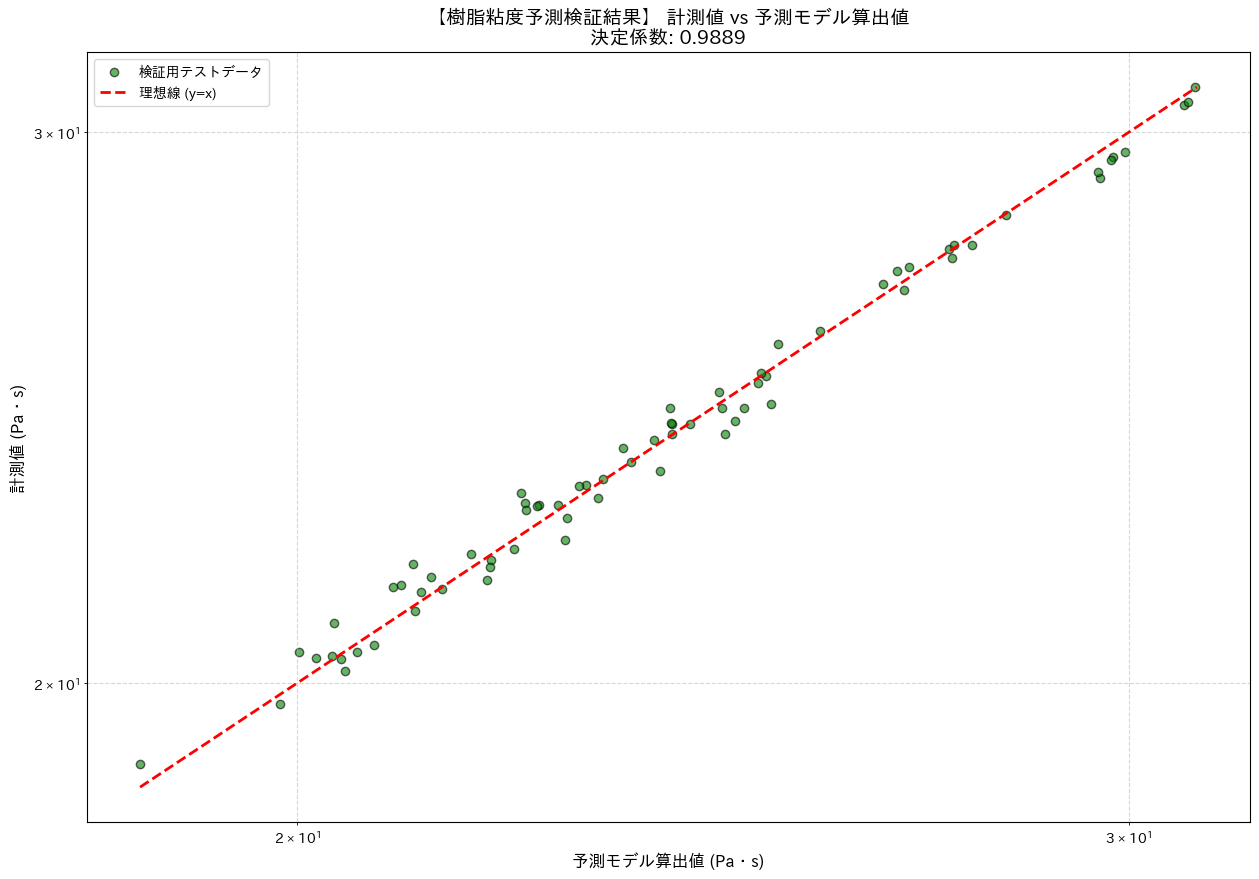

決定係数(R2): 0.9889 (1に近いほど高精度)
>> 判定: 【合格】 未知のデータに対しても高い予測精度が出ています。


In [7]:
#セル7テストデータを用いた粘度予測モデルの精度検証


import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error

if learning_completed:
    print("\n--- 検証結果の可視化 (精度検証) ---")
    
    # === 1. パリティプロット (精度検証) ===
    # テストデータに対する予測
    y_pred_test_centered, y_std_test = gp_model.predict(X_test, return_std=True)
    
    # 実数値に戻す
    y_test_real = np.exp(y_test + y_mean)
    y_pred_real = np.exp(y_pred_test_centered + y_mean)
    
    # 精度スコア
    r2 = r2_score(y_test_real, y_pred_real)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    
    # パリティプロット
    plt.figure(figsize=(15, 10))
    plt.scatter(y_pred_real, y_test_real, c='green', alpha=0.6, edgecolors='k', label='検証用テストデータ')
    
    # 理想線
    min_val = min(y_test_real.min(), y_pred_real.min())
    max_val = max(y_test_real.max(), y_pred_real.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='理想線 (y=x)')
    
    plt.xscale('log'); plt.yscale('log')
    plt.title(f"【樹脂粘度予測検証結果】 計測値 vs 予測モデル算出値\n決定係数: {r2:.4f}", fontsize=14)  #\n分割モード: {split_mode}
    plt.xlabel("予測モデル算出値 (Pa・s)", fontsize=12)
    plt.ylabel("計測値 (Pa・s)", fontsize=12)
    plt.legend(); plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.show()
    
    print(f"決定係数(R2): {r2:.4f} (1に近いほど高精度)")
    if r2 > 0.95:
        print(">> 判定: 【合格】 未知のデータに対しても高い予測精度が出ています。")
    else:
        print(">> 判定: 【注意】 テストデータの予測精度が低めです。過学習またはデータの範囲外予測の可能性があります。")

In [8]:
# セル8：学習済みモデルの保存
import os
import joblib

if 'gp_model' in locals() and learning_completed:
    # 1. セル2で選択したCSVファイルの「ディレクトリ（フォルダの場所）」を取得
    base_dir = os.path.dirname(csv_file_path)
    
    # 2. 保存するファイル名を決定
    file_name = 'viscosity_model.pkl'
    
    # 3. パスを結合して、保存先のフルパスを作成
    save_path = os.path.join(base_dir, file_name)
    
    # 4. モデルの保存
    joblib.dump(gp_model, save_path)
    
    print("--- モデル保存完了 ---")
    print(f"保存ファイル名: {file_name}")
    print(f"保存先フォルダ: {base_dir}")
    print(f"フルパス: {save_path}")

else:
    print("エラー: モデルが学習されていないため、保存できません。")

--- モデル保存完了 ---
保存ファイル名: viscosity_model.pkl
保存先フォルダ: C:/Users/0uh2j/OneDrive/Desktop/　機械学習準備　変数間調査/学習データ‗全キャビティ_樹脂温度ずつ/9ショット分/ノイズショット抜きデータ/ノイズショット抜きデータ_全加熱シリンダ温度
フルパス: C:/Users/0uh2j/OneDrive/Desktop/　機械学習準備　変数間調査/学習データ‗全キャビティ_樹脂温度ずつ/9ショット分/ノイズショット抜きデータ/ノイズショット抜きデータ_全加熱シリンダ温度\viscosity_model.pkl


樹脂粘度予測モデル(表示ひとつの変数を固定した三次元グラフ)の作成準備：固定する値をその変数における平均値に設定

In [9]:
# セル9
import numpy as np

if 'X_raw' in locals() and 'df' in locals():
    print("--- 3Dグラフ描画の準備 ---")
    
    # 元データの最小値・最大値・中央値を取得（グラフの範囲と固定値に使用）
    # X_rawの列順序: 0:温度(log), 1:圧力(log), 2:せん断速度(log)
    
    # --- 温度 (Temperature) ---
    temp_min = np.exp(X_raw[:, 0].min()) - 273.15
    temp_max = np.exp(X_raw[:, 0].max()) - 273.15
    temp_med = np.exp(np.median(X_raw[:, 0])) - 273.15
    
    # --- 圧力 (Pressure) ---
    pres_min = np.exp(X_raw[:, 1].min())
    pres_max = np.exp(X_raw[:, 1].max())
    pres_med = np.exp(np.median(X_raw[:, 1]))
    
    # --- せん断速度 (Shear Rate) ---
    sr_min = np.exp(X_raw[:, 2].min())
    sr_max = np.exp(X_raw[:, 2].max())
    sr_med = np.exp(np.median(X_raw[:, 2]))

    print(f"【算出された固定値のデフォルト(データの中央値)】")
    print(f"  - 温度固定時の値: {temp_med:.2f} ℃")
    print(f"  - 圧力固定時の値: {pres_med:.2e} Pa")
    print(f"  - せん断速度固定時の値: {sr_med:.2f} 1/s")
    print("準備完了。以下のセル10～12でグラフを描画できます。")
else:
    print("エラー: データを読み込み、学習を完了させてから実行してください。")

--- 3Dグラフ描画の準備 ---
【算出された固定値のデフォルト(データの中央値)】
  - 温度固定時の値: 210.05 ℃
  - 圧力固定時の値: 5.35e+06 Pa
  - せん断速度固定時の値: 5600.00 1/s
準備完了。以下のセル10～12でグラフを描画できます。


樹脂粘度vsせん断速度and流動中温度(モデルの部分像)

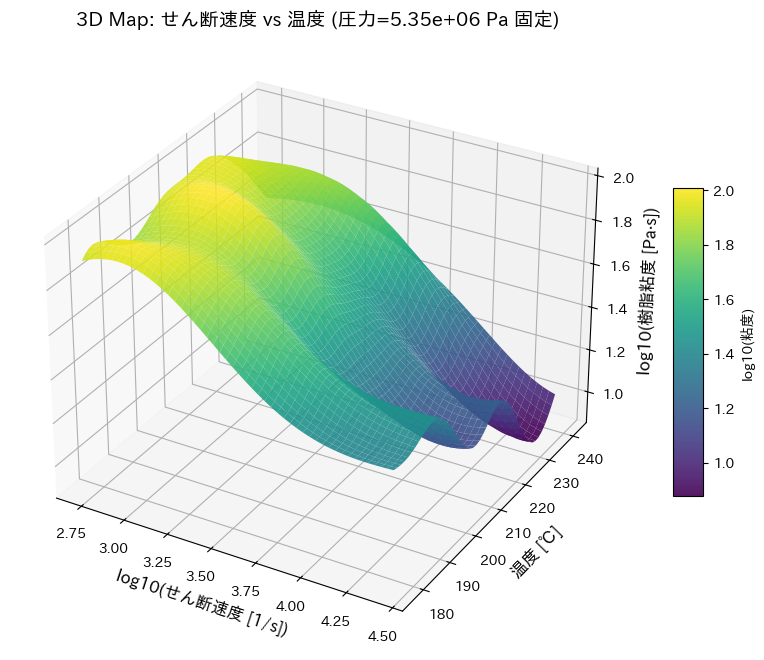

In [ ]:

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# === 設定エリア：固定する値を変更したい場合はここを書き換えてください ===
FIXED_PRESSURE = pres_med  # デフォルトは中央値 (単位: Pa)
# ===================================================================

if learning_completed:
    # 1. グリッドデータの作成
    n_grid = 50
    # せん断速度 (対数等間隔)
    sr_mesh = np.geomspace(sr_min, sr_max, n_grid)
    # 温度 (線形等間隔)
    temp_mesh = np.linspace(temp_min, temp_max, n_grid)
    
    X_grid, Y_grid = np.meshgrid(sr_mesh, temp_mesh) # X:SR, Y:Temp
    
    # 2. モデル入力用データへの変換
    # 温度(K)のlog
    log_T_in = np.log(Y_grid.ravel() + 273.15)
    # 圧力(Pa)のlog (固定値)
    log_P_in = np.full_like(log_T_in, np.log(FIXED_PRESSURE))
    # せん断速度(1/s)のlog
    log_SR_in = np.log(X_grid.ravel())
    
    # 配列結合 [Temp, Pres, SR] の順番に注意
    X_input_raw = np.stack([log_T_in, log_P_in, log_SR_in], axis=1)
    
    # 標準化
    X_input_scaled = scaler.transform(X_input_raw)
    
    # 3. 予測
    y_pred_scaled = gp_model.predict(X_input_scaled)
    
    # 4. 実数値へ逆変換 (粘度)
    visc_pred = np.exp(y_pred_scaled + y_mean).reshape(X_grid.shape)
    
    # 5. 3Dプロット
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # サーフェス描画
    surf = ax.plot_surface(np.log10(X_grid), Y_grid, np.log10(visc_pred), 
                           cmap=cm.viridis, edgecolor='none', alpha=0.9)
    
    ax.set_title(f"3D Map: せん断速度 vs 温度 (圧力={FIXED_PRESSURE:.2e} Pa 固定)", fontsize=14)
    ax.set_xlabel('log10(せん断速度 [1/s])', fontsize=12)
    ax.set_ylabel('温度 [℃]', fontsize=12)
    ax.set_zlabel('log10(樹脂粘度 [Pa·s])', fontsize=12)
    
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='log10(粘度)')
    plt.show()

樹脂粘度vsせん断速度and流動中圧力(モデルの部分像)

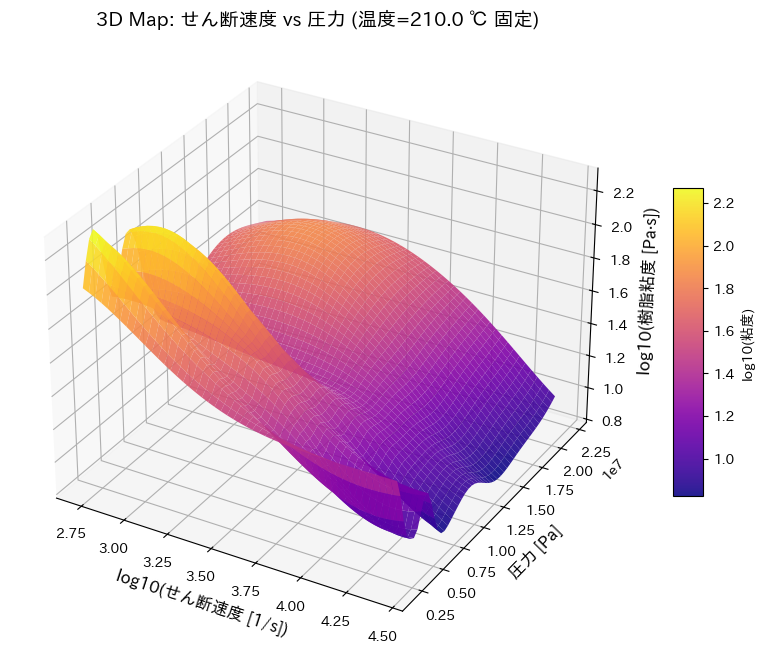

In [11]:
# セル11
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# === 設定エリア ===
FIXED_TEMP = temp_med  # デフォルトは中央値 (単位: ℃)
# ==================

if learning_completed:
    # 1. グリッド作成
    n_grid = 50
    sr_mesh = np.geomspace(sr_min, sr_max, n_grid)
    pres_mesh = np.linspace(pres_min, pres_max, n_grid) # 圧力は線形で作成
    
    X_grid, Y_grid = np.meshgrid(sr_mesh, pres_mesh) # X:SR, Y:Pres
    
    # 2. モデル入力作成
    log_T_in = np.full_like(X_grid.ravel(), np.log(FIXED_TEMP + 273.15)) # 固定
    log_P_in = np.log(Y_grid.ravel())
    log_SR_in = np.log(X_grid.ravel())
    
    X_input_raw = np.stack([log_T_in, log_P_in, log_SR_in], axis=1)
    X_input_scaled = scaler.transform(X_input_raw)
    
    # 3. 予測
    y_pred_scaled = gp_model.predict(X_input_scaled)
    visc_pred = np.exp(y_pred_scaled + y_mean).reshape(X_grid.shape)
    
    # 4. プロット
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    surf = ax.plot_surface(np.log10(X_grid), Y_grid, np.log10(visc_pred), 
                           cmap=cm.plasma, edgecolor='none', alpha=0.9)
    
    ax.set_title(f"3D Map: せん断速度 vs 圧力 (温度={FIXED_TEMP:.1f} ℃ 固定)", fontsize=14)
    ax.set_xlabel('log10(せん断速度 [1/s])', fontsize=12)
    ax.set_ylabel('圧力 [Pa]', fontsize=12)
    ax.set_zlabel('log10(樹脂粘度 [Pa·s])', fontsize=12)
    
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='log10(粘度)')
    plt.show()

樹脂粘度vs流動中温度and流動中圧力(モデルの部分像)

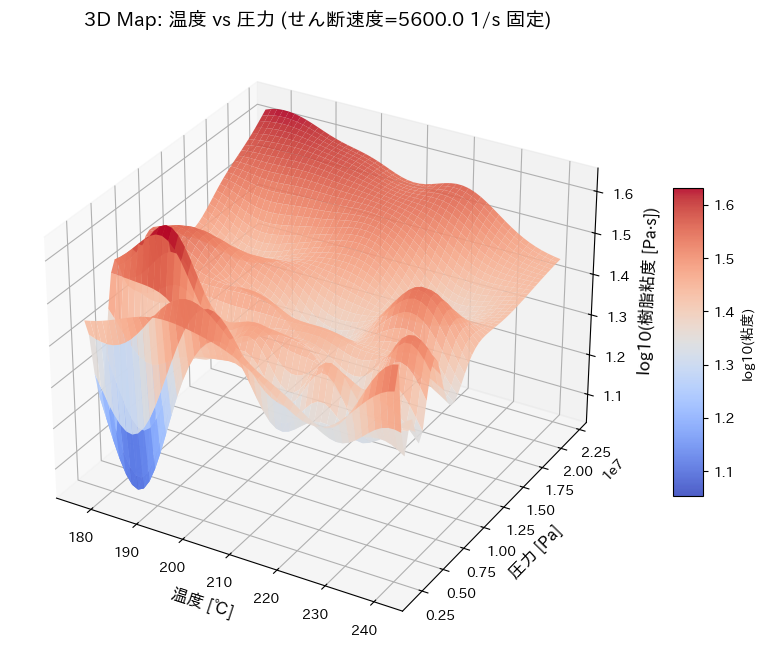

In [12]:
# セル12
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

# === 設定エリア ===
FIXED_SR = sr_med  # デフォルトは中央値 (単位: 1/s)
# ==================

if learning_completed:
    # 1. グリッド作成
    n_grid = 50
    temp_mesh = np.linspace(temp_min, temp_max, n_grid)
    pres_mesh = np.linspace(pres_min, pres_max, n_grid)
    
    X_grid, Y_grid = np.meshgrid(temp_mesh, pres_mesh) # X:Temp, Y:Pres
    
    # 2. モデル入力作成
    log_T_in = np.log(X_grid.ravel() + 273.15)
    log_P_in = np.log(Y_grid.ravel())
    log_SR_in = np.full_like(log_T_in, np.log(FIXED_SR)) # 固定
    
    X_input_raw = np.stack([log_T_in, log_P_in, log_SR_in], axis=1)
    X_input_scaled = scaler.transform(X_input_raw)
    
    # 3. 予測
    y_pred_scaled = gp_model.predict(X_input_scaled)
    visc_pred = np.exp(y_pred_scaled + y_mean).reshape(X_grid.shape)
    
    # 4. プロット
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    surf = ax.plot_surface(X_grid, Y_grid, np.log10(visc_pred), 
                           cmap=cm.coolwarm, edgecolor='none', alpha=0.9)
    
    ax.set_title(f"3D Map: 温度 vs 圧力 (せん断速度={FIXED_SR:.1f} 1/s 固定)", fontsize=14)
    ax.set_xlabel('温度 [℃]', fontsize=12)
    ax.set_ylabel('圧力 [Pa]', fontsize=12)
    ax.set_zlabel('log10(樹脂粘度 [Pa·s])', fontsize=12)
    
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label='log10(粘度)')
    plt.show()